<a href="https://colab.research.google.com/github/ixchelalvaradoz24-dot/AF3_PENDULO_ROBOT_CODE/blob/main/C%C3%B3digo_AF3_MSDSM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

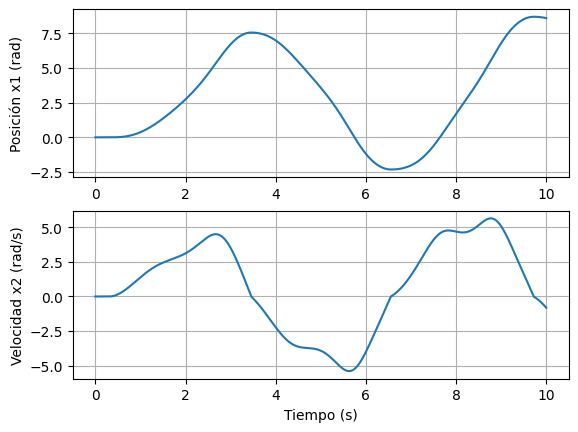

In [41]:

import numpy as np
import matplotlib.pyplot as plt

# ---------- Parámetros ----------
Ir  = 0.16
m   = 5
g   = 9.81
lc  = 0.01
b   = 0.14
fc  = 0.45
tau = 0.8                # par del motor (supuesto, N·m)

J = Ir     # inercia respecto al pivote

# ---------- Configuración de la simulación ----------
dt = 0.001               # paso de tiempo (s)
T  = 10                  # tiempo total (s)
N  = int(T / dt)         # número de pasos

t  = np.zeros(N)         # arreglos de N ceros (historial)
x1 = np.zeros(N)         # posición (rad)
x2 = np.zeros(N)         # velocidad (rad/s)
# Condiciones iniciales: x1[0] = 0 y x2[0] = 0, ya quedaron en cero

# ---------- Simulación ----------
for k in range(N - 1):
    tau = 1.5 * np.sin(t[k])  # el par se calcula en cada paso
    x2_punto = (tau - m*g*lc*np.sin(x1[k]) - b*x2[k] - fc*np.sign(x2[k])) / J
    x1[k+1] = x1[k] + x2[k] * dt
    x2[k+1] = x2[k] + x2_punto * dt
    t[k+1]  = t[k] + dt

# ---------- Gráficas ----------
plt.subplot(2, 1, 1)
plt.plot(t, x1)
plt.ylabel("Posición x1 (rad)")
plt.grid()

plt.subplot(2, 1, 2)
plt.plot(t, x2)
plt.ylabel("Velocidad x2 (rad/s)")
plt.xlabel("Tiempo (s)")
plt.grid()

plt.show()